# Smart Energy Planner — Research Notebook

Ilias Moulouki · AUI · AI specialization

Research in progress. Preserved code and outputs from the uploaded notebook. Headings added for navigation. Sections 1–7 contain exploratory results; section 8 uses preprocessing fitted on the selected 500 examples. Test-year evaluation and battery/QAOA scheduling remain unfinished. Run code cells in order; quantum training can take several minutes per run.


In [ ]:
print("Smart Energy Planner")

Smart Energy Planner


# 1. Dataset acquisition

UCI dataset 235. Data are downloaded at runtime; raw data are not committed.


In [ ]:
%pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=235)

/usr/local/lib/python3.13/dist-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


In [ ]:
df = dataset.data.features.copy()
display(df.head())



,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [ ]:
demand = df[["Date", "Time", "Global_active_power"]].copy()

display(demand.head())

,Date,Time,Global_active_power
0,16/12/2006,17:24:00,4.216
1,16/12/2006,17:25:00,5.360
2,16/12/2006,17:26:00,5.374
3,16/12/2006,17:27:00,5.388
4,16/12/2006,17:28:00,3.666


# 2. Cleaning and hourly aggregation

Demand is mean power in kW. Keep only hours with 60 minute observations.


In [ ]:
import pandas as pd

demand["timestamp"] = pd.to_datetime(
    demand["Date"] + " " + demand["Time"],
    format="%d/%m/%Y %H:%M:%S"
)

display(demand.head())

,Date,Time,Global_active_power,timestamp
0,16/12/2006,17:24:00,4.216,2006-12-16 17:24:00
1,16/12/2006,17:25:00,5.360,2006-12-16 17:25:00
2,16/12/2006,17:26:00,5.374,2006-12-16 17:26:00
3,16/12/2006,17:27:00,5.388,2006-12-16 17:27:00
4,16/12/2006,17:28:00,3.666,2006-12-16 17:28:00


In [ ]:
demand["Global_active_power"] = pd.to_numeric(
    demand["Global_active_power"],
    errors="coerce"
)

print(demand["Global_active_power"].isna().sum())

25979


In [ ]:
missing_percentage = demand["Global_active_power"].isna().mean() * 100

print(f"Missing readings: {missing_percentage:.2f}%")

Missing readings: 1.25%


In [ ]:
hourly = demand.resample("h", on="timestamp")["Global_active_power"].agg(
    ["mean", "count"]
)

display(hourly.head())

,mean,count
timestamp,,
2006-12-16 17:00:00,4.222889,36
2006-12-16 18:00:00,3.632200,60
2006-12-16 19:00:00,3.400233,60
2006-12-16 20:00:00,3.268567,60
2006-12-16 21:00:00,3.056467,60


In [ ]:
hourly["demand_kw"] = hourly["mean"].where(hourly["count"] == 60)

display(hourly.head())

,mean,count,demand_kw
timestamp,,,
2006-12-16 17:00:00,4.222889,36,NaN
2006-12-16 18:00:00,3.632200,60,3.632200
2006-12-16 19:00:00,3.400233,60,3.400233
2006-12-16 20:00:00,3.268567,60,3.268567
2006-12-16 21:00:00,3.056467,60,3.056467


In [ ]:
print("Total hours:", len(hourly))
print("Usable hours:", hourly["demand_kw"].notna().sum())
print("Incomplete hours:", hourly["demand_kw"].isna().sum())

Total hours: 34589
Usable hours: 34085
Incomplete hours: 504


In [ ]:
print("Duplicate timestamps:", demand["timestamp"].duplicated().sum())

Duplicate timestamps: 0


17 October 2026 — Data preparation
- Loaded the household electricity dataset.
- Combined date and time into a timestamp.
- Found 25,979 missing power readings: approximately 1.25%.
- Calculated hourly average power demand.
- Required 60 valid minute readings for a usable hour.
- Obtained 34,085 usable hours and 504 incomplete hours.
- Kept incomplete hours as missing to preserve the timeline.
- Confirmed there are no duplicate timestamps.

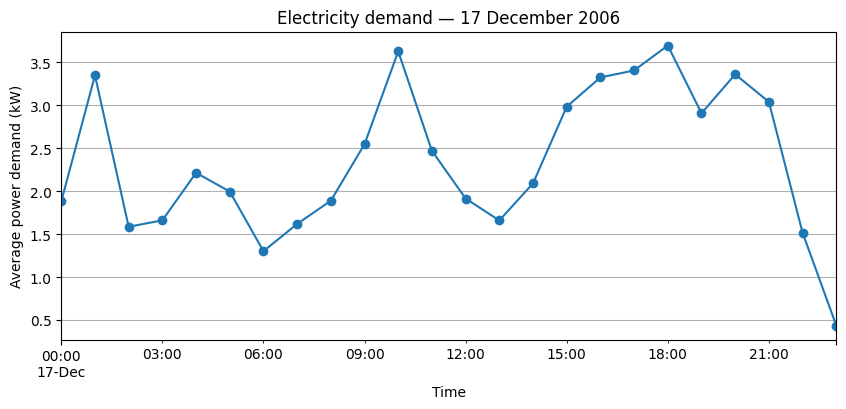

In [ ]:
import matplotlib.pyplot as plt

day = hourly.loc["2006-12-17", "demand_kw"]

day.plot(figsize=(10, 4), marker="o")
plt.title("Electricity demand — 17 December 2006")
plt.xlabel("Time")
plt.ylabel("Average power demand (kW)")
plt.grid(True)
plt.show()

# 3. Initial forecasting baselines

Exploratory one- and two-input models. Evaluation row counts differ from later experiments.


In [ ]:
forecast_data = hourly[["demand_kw"]].copy()

forecast_data["previous_hour_kw"] = forecast_data["demand_kw"].shift(1)

display(forecast_data.head())

,demand_kw,previous_hour_kw
timestamp,,
2006-12-16 17:00:00,NaN,NaN
2006-12-16 18:00:00,3.632200,NaN
2006-12-16 19:00:00,3.400233,3.632200
2006-12-16 20:00:00,3.268567,3.400233
2006-12-16 21:00:00,3.056467,3.268567


In [ ]:
examples = forecast_data.dropna(
    subset=["previous_hour_kw", "demand_kw"]
).copy()

display(examples.head())
print("Usable prediction examples:", len(examples))

,demand_kw,previous_hour_kw
timestamp,,
2006-12-16 19:00:00,3.400233,3.632200
2006-12-16 20:00:00,3.268567,3.400233
2006-12-16 21:00:00,3.056467,3.268567
2006-12-16 22:00:00,2.200133,3.056467
2006-12-16 23:00:00,2.061600,2.200133


Usable prediction examples: 34016


In [ ]:
train = examples.loc["2007":"2008"].copy()
validation = examples.loc["2009"].copy()
test = examples.loc["2010"].copy()

print("Training examples:", len(train))
print("Validation examples:", len(validation))
print("Testing examples:", len(test))

Training examples: 17405
Validation examples: 8656
Testing examples: 7594


In [ ]:
validation["persistence_prediction"] = validation["previous_hour_kw"]

display(
    validation[["demand_kw", "persistence_prediction"]].head()
)

,demand_kw,persistence_prediction
timestamp,,
2009-01-01 00:00:00,0.534933,0.575433
2009-01-01 01:00:00,0.540467,0.534933
2009-01-01 02:00:00,0.575367,0.540467
2009-01-01 03:00:00,0.526500,0.575367
2009-01-01 04:00:00,0.521900,0.526500


In [ ]:
absolute_errors = (
    validation["demand_kw"] - validation["persistence_prediction"]
).abs()

mae = absolute_errors.mean()

print(f"Persistence MAE: {mae:.4f} kW")

Persistence MAE: 0.4284 kW


Persistence baseline: validation MAE of 0.4284 kW for one-hour-ahead demand prediction on 2009 data. Final test data remains unused.

In [ ]:
X_train = train[["previous_hour_kw"]]
y_train = train["demand_kw"]

display(X_train.head())
display(y_train.head())

,previous_hour_kw
timestamp,
2007-01-01 00:00:00,3.104433
2007-01-01 01:00:00,2.550633
2007-01-01 02:00:00,2.523400
2007-01-01 03:00:00,2.582333
2007-01-01 04:00:00,2.541667


,demand_kw
timestamp,
2007-01-01 00:00:00,2.550633
2007-01-01 01:00:00,2.523400
2007-01-01 02:00:00,2.582333
2007-01-01 03:00:00,2.541667
2007-01-01 04:00:00,2.475733


In [ ]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

print("a:", linear_model.coef_[0])
print("b:", linear_model.intercept_)

a: 0.7213429241788861
b: 0.30421590168512125


In [ ]:
validation["linear_prediction"] = linear_model.predict(
    validation[["previous_hour_kw"]]
)

linear_mae = (
    validation["demand_kw"] - validation["linear_prediction"]
).abs().mean()

print(f"Linear Regression MAE: {linear_mae:.4f} kW")

Linear Regression MAE: 0.4322 kW


With previous-hour demand as the only input, Linear Regression achieved a validation MAE of 0.4322 kW, slightly worse than persistence at 0.4284 kW.

In [ ]:
forecast_data["previous_day_kw"] = hourly["demand_kw"].shift(24)

display(forecast_data.iloc[24:29])

,demand_kw,previous_hour_kw,previous_day_kw
timestamp,,,
2006-12-17 17:00:00,3.406767,3.326033,NaN
2006-12-17 18:00:00,3.697100,3.406767,3.632200
2006-12-17 19:00:00,2.908400,3.697100,3.400233
2006-12-17 20:00:00,3.361500,2.908400,3.268567
2006-12-17 21:00:00,3.040767,3.361500,3.056467


In [ ]:
examples_two = forecast_data.dropna(
    subset=["previous_hour_kw", "previous_day_kw", "demand_kw"]
).copy()

train_two = examples_two.loc["2007":"2008"].copy()
validation_two = examples_two.loc["2009"].copy()

print("Training examples:", len(train_two))
print("Validation examples:", len(validation_two))

Training examples: 17341
Validation examples: 8602


In [ ]:
features = ["previous_hour_kw", "previous_day_kw"]

linear_two = LinearRegression()
linear_two.fit(train_two[features], train_two["demand_kw"])

print("Previous-hour coefficient:", linear_two.coef_[0])
print("Previous-day coefficient:", linear_two.coef_[1])
print("Intercept:", linear_two.intercept_)

Previous-hour coefficient: 0.6494845385147217
Previous-day coefficient: 0.19202255446295274
Intercept: 0.17274612172070036


In [ ]:
predictions_two = linear_two.predict(validation_two[features])

mae_two = (
    validation_two["demand_kw"] - predictions_two
).abs().mean()

mae_persistence_same = (
    validation_two["demand_kw"] - validation_two["previous_hour_kw"]
).abs().mean()

print(f"Two-input Linear Regression MAE: {mae_two:.4f} kW")
print(f"Persistence MAE on the same rows: {mae_persistence_same:.4f} kW")

Two-input Linear Regression MAE: 0.4131 kW
Persistence MAE on the same rows: 0.4291 kW


In [ ]:
predictions_one = linear_model.predict(
    validation_two[["previous_hour_kw"]]
)

mae_one_same = (
    validation_two["demand_kw"] - predictions_one
).abs().mean()

print(f"One-input Linear Regression MAE: {mae_one_same:.4f} kW")

One-input Linear Regression MAE: 0.4328 kW


In [ ]:
linear_one_matched = LinearRegression()
linear_one_matched.fit(
    train_two[["previous_hour_kw"]],
    train_two["demand_kw"]
)

predictions = linear_one_matched.predict(
    validation_two[["previous_hour_kw"]]
)

mae_one_matched = (
    validation_two["demand_kw"] - predictions
).abs().mean()

print(f"Matched one-input MAE: {mae_one_matched:.4f} kW")

Matched one-input MAE: 0.4328 kW


Compared three forecasting methods on 8,602 validation examples. With identical training rows, adding previous-day demand reduced Linear Regression MAE from 0.4328 to 0.4131 kW. Persistence achieved 0.4291 kW. Final test data remains unused.

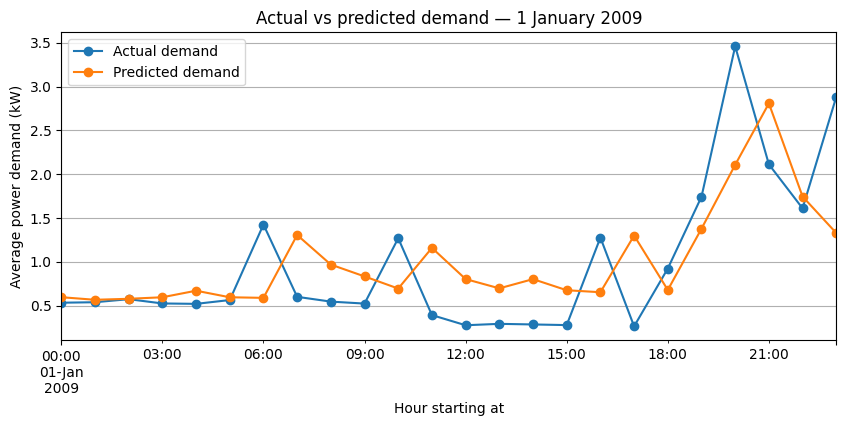

In [ ]:
validation_two["linear_prediction"] = predictions_two

comparison = validation_two.loc[
    "2009-01-01", ["demand_kw", "linear_prediction"]
].asfreq("h")

comparison.plot(figsize=(10, 4), marker="o")
plt.title("Actual vs predicted demand — 1 January 2009")
plt.xlabel("Hour starting at")
plt.ylabel("Average power demand (kW)")
plt.legend(["Actual demand", "Predicted demand"])
plt.grid(True)
plt.show()

# 4. Four-input classical forecasting

Previous hour, previous day, and sine/cosine of hour. These initial models use the full training pool.


In [ ]:
forecast_data["hour"] = forecast_data.index.hour

display(
    forecast_data[["demand_kw", "previous_hour_kw", "previous_day_kw", "hour"]].tail()
)

,demand_kw,previous_hour_kw,previous_day_kw,hour
timestamp,,,,
2010-11-26 17:00:00,1.725900,1.067933,1.480100,17
2010-11-26 18:00:00,1.573467,1.725900,2.211600,18
2010-11-26 19:00:00,1.659333,1.573467,2.330467,19
2010-11-26 20:00:00,1.163700,1.659333,1.647833,20
2010-11-26 21:00:00,NaN,1.163700,1.342933,21


In [ ]:
import numpy as np

forecast_data["hour_sin"] = np.sin(
    2 * np.pi * forecast_data["hour"] / 24
)

forecast_data["hour_cos"] = np.cos(
    2 * np.pi * forecast_data["hour"] / 24
)

display(forecast_data[["hour", "hour_sin", "hour_cos"]].head())

,hour,hour_sin,hour_cos
timestamp,,,
2006-12-16 17:00:00,17,-0.965926,-2.588190e-01
2006-12-16 18:00:00,18,-1.000000,-1.836970e-16
2006-12-16 19:00:00,19,-0.965926,2.588190e-01
2006-12-16 20:00:00,20,-0.866025,5.000000e-01
2006-12-16 21:00:00,21,-0.707107,7.071068e-01


In [ ]:
features_four = [
    "previous_hour_kw",
    "previous_day_kw",
    "hour_sin",
    "hour_cos"
]

examples_four = forecast_data.dropna(
    subset=features_four + ["demand_kw"]
).copy()

train_four = examples_four.loc["2007":"2008"].copy()
validation_four = examples_four.loc["2009"].copy()

print("Training examples:", len(train_four))
print("Validation examples:", len(validation_four))

Training examples: 17341
Validation examples: 8602


In [ ]:
linear_four = LinearRegression()

linear_four.fit(
    train_four[features_four],
    train_four["demand_kw"]
)

predictions_four = linear_four.predict(
    validation_four[features_four]
)

mae_four = (
    validation_four["demand_kw"] - predictions_four
).abs().mean()

print(f"Four-input Linear Regression MAE: {mae_four:.4f} kW")

Four-input Linear Regression MAE: 0.4069 kW


Adding hour-of-day sine and cosine features reduced validation MAE from 0.4131 to 0.4069 kW, approximately a 1.5% improvement. The four-input linear regression also achieved approximately 5.2% lower MAE than persistence on the same validation hours. These results concern demand forecasting; their effect on energy costs remains to be tested.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(
    train_four[features_four],
    train_four["demand_kw"]
)

print("Random Forest training complete.")

Random Forest training complete.


In [ ]:
predictions_forest = forest_model.predict(
    validation_four[features_four]
)

mae_forest = (
    validation_four["demand_kw"] - predictions_forest
).abs().mean()

print(f"Random Forest MAE: {mae_forest:.4f} kW")
print(f"Four-input Linear Regression MAE: {mae_four:.4f} kW")

Random Forest MAE: 0.3689 kW
Four-input Linear Regression MAE: 0.4069 kW


Random Forest, using previous-hour demand, previous-day demand, and two cyclic hour features, achieved a validation MAE of 0.3689 kW. This was approximately 9.3% lower than four-input linear regression and 14.0% lower than persistence on the same validation hours. The final test set remains unused.


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(
    train_four[features_four]
)

X_validation_scaled = scaler.transform(
    validation_four[features_four]
)

print("Inputs scaled successfully.")

Inputs scaled successfully.


In [ ]:
from sklearn.neural_network import MLPRegressor

mlp_model = MLPRegressor(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42
)

mlp_model.fit(
    X_train_scaled,
    train_four["demand_kw"]
)

print("Neural network training complete.")

Neural network training complete.


In [ ]:
predictions_mlp = mlp_model.predict(X_validation_scaled)

mae_mlp = (
    validation_four["demand_kw"] - predictions_mlp
).abs().mean()

print(f"Neural Network MAE: {mae_mlp:.4f} kW")
print(f"Random Forest MAE: {mae_forest:.4f} kW")
print(f"Linear Regression MAE: {mae_four:.4f} kW")

Neural Network MAE: 0.3711 kW
Random Forest MAE: 0.3689 kW
Linear Regression MAE: 0.4069 kW


The small neural network, with hidden layers of 16 and 8 neurons, achieved a validation MAE of 0.3711 kW using four standardized inputs. Scaling was fitted on training data only. Random Forest remained slightly better at 0.3689 kW. These are initial results from one configuration and one random seed per model; the final test set remains unused.

# 5. One-block VQC pilot

Four qubits, statevector simulation. The pilot scaler was fitted on the full training pool; limited-data final comparisons appear later.


In [ ]:
X_train_angles = np.arctan(X_train_scaled)
X_validation_angles = np.arctan(X_validation_scaled)

print("First training example as angles:")
print(X_train_angles[0])

First training example as angles:
[ 1.12915275 -0.41229135 -0.00403675  0.95460469]


In [ ]:
%pip install qiskit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 42.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 83.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]


In [ ]:
import qiskit

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.6.1


In [ ]:
from qiskit import QuantumCircuit

example_circuit = QuantumCircuit(4)

for i in range(4):
    example_circuit.ry(float(X_train_angles[0, i]), i)

display(example_circuit.draw(output="text"))

┌────────────┐  
q_0: ──┤ Ry(1.1292) ├──
      ┌┴────────────┴┐ 
q_1: ─┤ Ry(-0.41229) ├─
     ┌┴──────────────┴┐
q_2: ┤ Ry(-0.0040368) ├
     └─┬────────────┬─┘
q_3: ──┤ Ry(0.9546) ├──
       └────────────┘

In [ ]:
from qiskit.circuit import ParameterVector

theta = ParameterVector("theta", length=4)

trainable_circuit = example_circuit.copy()
trainable_circuit.barrier()

for i in range(4):
    trainable_circuit.ry(theta[i], i)

display(trainable_circuit.draw(output="text"))

┌────────────┐   ░ ┌──────────────┐
q_0: ──┤ Ry(1.1292) ├───░─┤ Ry(theta[0]) ├
      ┌┴────────────┴┐  ░ ├──────────────┤
q_1: ─┤ Ry(-0.41229) ├──░─┤ Ry(theta[1]) ├
     ┌┴──────────────┴┐ ░ ├──────────────┤
q_2: ┤ Ry(-0.0040368) ├─░─┤ Ry(theta[2]) ├
     └─┬────────────┬─┘ ░ ├──────────────┤
q_3: ──┤ Ry(0.9546) ├───░─┤ Ry(theta[3]) ├
       └────────────┘   ░ └──────────────┘

In [ ]:
connected_circuit = trainable_circuit.copy()

connected_circuit.cx(0, 1)
connected_circuit.cx(1, 2)
connected_circuit.cx(2, 3)

display(connected_circuit.draw(output="text"))

┌────────────┐   ░ ┌──────────────┐               
q_0: ──┤ Ry(1.1292) ├───░─┤ Ry(theta[0]) ├──■────────────
      ┌┴────────────┴┐  ░ ├──────────────┤┌─┴─┐          
q_1: ─┤ Ry(-0.41229) ├──░─┤ Ry(theta[1]) ├┤ X ├──■───────
     ┌┴──────────────┴┐ ░ ├──────────────┤└───┘┌─┴─┐     
q_2: ┤ Ry(-0.0040368) ├─░─┤ Ry(theta[2]) ├─────┤ X ├──■──
     └─┬────────────┬─┘ ░ ├──────────────┤     └───┘┌─┴─┐
q_3: ──┤ Ry(0.9546) ├───░─┤ Ry(theta[3]) ├──────────┤ X ├
       └────────────┘   ░ └──────────────┘          └───┘

In [ ]:
rng = np.random.default_rng(42)
initial_angles = rng.uniform(-0.5, 0.5, size=4)

parameter_values = {
    theta[i]: float(initial_angles[i])
    for i in range(4)
}

bound_circuit = connected_circuit.assign_parameters(parameter_values)

print("Starting trainable angles:")
print(initial_angles)

display(bound_circuit.draw(output="text"))

Starting trainable angles:
[ 0.27395605 -0.06112156  0.35859792  0.19736803]


┌────────────┐   ░  ┌─────────────┐                
q_0: ──┤ Ry(1.1292) ├───░──┤ Ry(0.27396) ├───■────────────
      ┌┴────────────┴┐  ░ ┌┴─────────────┴┐┌─┴─┐          
q_1: ─┤ Ry(-0.41229) ├──░─┤ Ry(-0.061122) ├┤ X ├──■───────
     ┌┴──────────────┴┐ ░ └─┬────────────┬┘└───┘┌─┴─┐     
q_2: ┤ Ry(-0.0040368) ├─░───┤ Ry(0.3586) ├──────┤ X ├──■──
     └─┬────────────┬─┘ ░  ┌┴────────────┤      └───┘┌─┴─┐
q_3: ──┤ Ry(0.9546) ├───░──┤ Ry(0.19737) ├───────────┤ X ├
       └────────────┘   ░  └─────────────┘           └───┘

In [ ]:
from qiskit.quantum_info import Statevector

state = Statevector.from_instruction(bound_circuit)

probabilities = state.probabilities([3])

print(f"Probability of 0: {probabilities[0]:.4f}")
print(f"Probability of 1: {probabilities[1]:.4f}")

Probability of 0: 0.5283
Probability of 1: 0.4717


In [ ]:
quantum_output = probabilities[0] - probabilities[1]

print(f"Quantum output: {quantum_output:.4f}")

Quantum output: 0.0567


In [ ]:
demo_scale = 2.0
demo_bias = 1.0

demo_prediction = demo_scale * quantum_output + demo_bias
actual_demand = train_four["demand_kw"].iloc[0]

print(f"Untrained prediction: {demo_prediction:.4f} kW")
print(f"Actual demand: {actual_demand:.4f} kW")
print(f"Absolute error: {abs(demo_prediction - actual_demand):.4f} kW")

Untrained prediction: 1.1133 kW
Actual demand: 2.5506 kW
Absolute error: 1.4373 kW


In [ ]:
def circuit_output(input_angles, weights):
    circuit = QuantumCircuit(4)

    for i in range(4):
        circuit.ry(float(input_angles[i]), i)
        circuit.ry(float(weights[i]), i)

    circuit.cx(0, 1)
    circuit.cx(1, 2)
    circuit.cx(2, 3)

    state = Statevector.from_instruction(circuit)
    probs = state.probabilities([3])

    return float(probs[0] - probs[1])


check_output = circuit_output(X_train_angles[0], initial_angles)
print(f"Quantum output: {check_output:.4f}")

Quantum output: 0.0567


In [ ]:
def predict_quantum(X_angles, parameters):
    weights = parameters[:4]
    scale = parameters[4]
    bias = parameters[5]

    outputs = np.array([
        circuit_output(row, weights)
        for row in X_angles
    ])

    return scale * outputs + bias


def quantum_mse(parameters, X_angles, y_actual):
    predictions = predict_quantum(X_angles, parameters)
    return np.mean((predictions - np.asarray(y_actual)) ** 2)


initial_parameters = np.concatenate([
    initial_angles,
    [demo_scale, demo_bias]
])

initial_error = quantum_mse(
    initial_parameters,
    X_train_angles[:10],
    train_four["demand_kw"].iloc[:10]
)

print(f"Initial MSE on 10 training examples: {initial_error:.4f} kW²")

Initial MSE on 10 training examples: 2.1190 kW²


In [ ]:
from scipy.optimize import minimize

demo_result = minimize(
    quantum_mse,
    initial_parameters,
    args=(
        X_train_angles[:10],
        train_four["demand_kw"].iloc[:10].to_numpy()
    ),
    method="L-BFGS-B",
    options={"maxiter": 50}
)

print(f"Before training: {initial_error:.4f} kW²")
print(f"After training: {demo_result.fun:.4f} kW²")
print("Optimizer message:", demo_result.message)

Before training: 2.1190 kW²
After training: 0.0020 kW²
Optimizer message: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT


Built a four-qubit demonstration circuit with input rotations, four trainable rotation angles, and three CNOT gates. A trainable scale and bias convert its output into kW. Training on 10 examples reduced MSE from 2.1190 to approximately 0.0020 kW², reaching the 50-iteration limit. This was a training-loop check, not a validation result.

# 6. Matched 500-example pilot

Fixed training subset. Scaling still comes from the full training pool, so these are pilot results.


In [ ]:
sample_rng = np.random.default_rng(42)

quantum_train_indices = np.sort(
    sample_rng.choice(
        len(train_four),
        size=500,
        replace=False
    )
)

X_quantum_train = X_train_angles[quantum_train_indices]

y_quantum_train = (
    train_four["demand_kw"]
    .iloc[quantum_train_indices]
    .to_numpy()
)

print("Quantum training examples:", len(y_quantum_train))
print(
    "Examples per year:",
    train_four.iloc[quantum_train_indices]
    .groupby(train_four.iloc[quantum_train_indices].index.year)
    .size()
    .to_dict()
)

Quantum training examples: 500
Examples per year: {2007: 256, 2008: 244}


In [ ]:
starting_mse = quantum_mse(
    initial_parameters,
    X_quantum_train,
    y_quantum_train
)

print(f"Starting training MSE: {starting_mse:.4f} kW²", flush=True)

quantum_result = minimize(
    quantum_mse,
    initial_parameters.copy(),
    args=(X_quantum_train, y_quantum_train),
    method="L-BFGS-B",
    options={"maxiter": 50}
)

print(f"Final training MSE: {quantum_result.fun:.4f} kW²")
print("Iterations:", quantum_result.nit)
print("Optimizer message:", quantum_result.message)

Starting training MSE: 1.5965 kW²
Final training MSE: 0.4736 kW²
Iterations: 20
Optimizer message: CONVERGENCE: NORM OF PROJECTED GRADIENT <= PGTOL


In [ ]:
quantum_parameters = quantum_result.x.copy()

predictions_quantum = predict_quantum(
    X_validation_angles,
    quantum_parameters
)

mae_quantum = np.mean(
    np.abs(
        validation_four["demand_kw"].to_numpy()
        - predictions_quantum
    )
)

print(f"Quantum model validation MAE: {mae_quantum:.4f} kW")

Quantum model validation MAE: 0.4450 kW


In [ ]:
linear_500 = LinearRegression()

linear_500.fit(
    train_four.iloc[quantum_train_indices][features_four],
    y_quantum_train
)

predictions_linear_500 = linear_500.predict(
    validation_four[features_four]
)

mae_linear_500 = np.mean(
    np.abs(
        validation_four["demand_kw"].to_numpy()
        - predictions_linear_500
    )
)

print(f"Linear Regression (500 examples) MAE: {mae_linear_500:.4f} kW")
print(f"Quantum model (500 examples) MAE: {mae_quantum:.4f} kW")

Linear Regression (500 examples) MAE: 0.4147 kW
Quantum model (500 examples) MAE: 0.4450 kW


In [ ]:
forest_500 = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

forest_500.fit(
    train_four.iloc[quantum_train_indices][features_four],
    y_quantum_train
)

predictions_forest_500 = forest_500.predict(
    validation_four[features_four]
)

mae_forest_500 = np.mean(
    np.abs(
        validation_four["demand_kw"].to_numpy()
        - predictions_forest_500
    )
)

print(f"Random Forest (500 examples) MAE: {mae_forest_500:.4f} kW")

Random Forest (500 examples) MAE: 0.4243 kW


In [ ]:
mlp_500 = MLPRegressor(
    hidden_layer_sizes=(16, 8),
    activation="relu",
    solver="adam",
    max_iter=500,
    random_state=42
)

mlp_500.fit(
    X_train_scaled[quantum_train_indices],
    y_quantum_train
)

predictions_mlp_500 = mlp_500.predict(X_validation_scaled)

mae_mlp_500 = np.mean(
    np.abs(
        validation_four["demand_kw"].to_numpy()
        - predictions_mlp_500
    )
)

print(f"Neural Network (500 examples) MAE: {mae_mlp_500:.4f} kW")

Neural Network (500 examples) MAE: 0.3905 kW


/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


Using the same 500 training examples and 8,602 validation hours, the neural network achieved the lowest MAE (0.3905 kW), followed by linear regression (0.4147), Random Forest (0.4243), and the initial quantum model (0.4450). The neural network reached its 500-iteration limit without convergence. These are preliminary results from one configuration and seed per model. The quantum model has not demonstrated an accuracy advantage.

# 7. Two-block VQC pilot

Architecture, extra-training, and initialization experiments. Do not mix with corrected-protocol results.


Experiment 2 — Effect of circuit depth
Investigate whether adding a second rotation-and-entanglement block improves demand forecasting. Compare accuracy and computational effort under matched data and preprocessing conditions. Improvement is not assumed.

In [ ]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector

inputs_v2 = ParameterVector("x", length=4)
weights_v2 = ParameterVector("w", length=8)

circuit_v2 = QuantumCircuit(4)

# Load the four input angles
for i in range(4):
    circuit_v2.ry(inputs_v2[i], i)

circuit_v2.barrier()

# Two blocks of trainable rotations and CNOT connections
for layer in range(2):
    for i in range(4):
        circuit_v2.ry(weights_v2[4 * layer + i], i)

    circuit_v2.cx(0, 1)
    circuit_v2.cx(1, 2)
    circuit_v2.cx(2, 3)

    circuit_v2.barrier()

display(circuit_v2.draw(output="text", fold=120))

┌──────────┐ ░ ┌──────────┐                ░ ┌──────────┐                ░ 
q_0: ┤ Ry(x[0]) ├─░─┤ Ry(w[0]) ├──■─────────────░─┤ Ry(w[4]) ├──■─────────────░─
     ├──────────┤ ░ ├──────────┤┌─┴─┐           ░ ├──────────┤┌─┴─┐           ░ 
q_1: ┤ Ry(x[1]) ├─░─┤ Ry(w[1]) ├┤ X ├──■────────░─┤ Ry(w[5]) ├┤ X ├──■────────░─
     ├──────────┤ ░ ├──────────┤└───┘┌─┴─┐      ░ ├──────────┤└───┘┌─┴─┐      ░ 
q_2: ┤ Ry(x[2]) ├─░─┤ Ry(w[2]) ├─────┤ X ├──■───░─┤ Ry(w[6]) ├─────┤ X ├──■───░─
     ├──────────┤ ░ ├──────────┤     └───┘┌─┴─┐ ░ ├──────────┤     └───┘┌─┴─┐ ░ 
q_3: ┤ Ry(x[3]) ├─░─┤ Ry(w[3]) ├──────────┤ X ├─░─┤ Ry(w[7]) ├──────────┤ X ├─░─
     └──────────┘ ░ └──────────┘          └───┘ ░ └──────────┘          └───┘ ░

In [ ]:
import numpy as np
from qiskit.quantum_info import Statevector

def circuit_output_v2(input_angles, weights):
    values = {
        inputs_v2[i]: float(input_angles[i])
        for i in range(4)
    }

    values.update({
        weights_v2[i]: float(weights[i])
        for i in range(8)
    })

    bound = circuit_v2.assign_parameters(values)
    state = Statevector.from_instruction(bound)
    probabilities = state.probabilities([3])

    return float(probabilities[0] - probabilities[1])


rng_v2 = np.random.default_rng(42)
initial_weights_v2 = rng_v2.uniform(-0.5, 0.5, size=8)

output_v2 = circuit_output_v2(
    X_train_angles[0],
    initial_weights_v2
)

print(f"Untrained circuit output: {output_v2:.4f}")

Untrained circuit output: 0.2676


In [ ]:
def predict_quantum_v2(X_angles, parameters):
    weights = parameters[:8]
    scale = parameters[8]
    bias = parameters[9]

    outputs = np.array([
        circuit_output_v2(row, weights)
        for row in X_angles
    ])

    return scale * outputs + bias


def quantum_mse_v2(parameters, X_angles, y_actual):
    predictions = predict_quantum_v2(X_angles, parameters)
    return np.mean((predictions - np.asarray(y_actual)) ** 2)


# Eight circuit weights, followed by scale and bias
initial_parameters_v2 = np.concatenate([
    initial_weights_v2,
    [2.0, 1.0]
])

starting_mse_v2 = quantum_mse_v2(
    initial_parameters_v2,
    X_quantum_train,
    y_quantum_train
)

print(f"Starting training MSE: {starting_mse_v2:.4f} kW²")


Starting training MSE: 1.8990 kW²


In [ ]:
from scipy.optimize import minimize
from time import perf_counter

start_time_v2 = perf_counter()

quantum_result_v2 = minimize(
    quantum_mse_v2,
    initial_parameters_v2.copy(),
    args=(X_quantum_train, y_quantum_train),
    method="L-BFGS-B",
    options={"maxiter": 50}
)

training_seconds_v2 = perf_counter() - start_time_v2
quantum_parameters_v2 = quantum_result_v2.x.copy()

print(f"Starting training MSE: {starting_mse_v2:.4f} kW²")
print(f"Final training MSE: {quantum_result_v2.fun:.4f} kW²")
print(f"Iterations: {quantum_result_v2.nit}")
print(f"Training time: {training_seconds_v2:.1f} seconds")
print(f"Optimizer success: {quantum_result_v2.success}")
print(f"Optimizer message: {quantum_result_v2.message}")

Starting training MSE: 1.8990 kW²
Final training MSE: 0.4215 kW²
Iterations: 50
Training time: 465.2 seconds
Optimizer success: False
Optimizer message: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT


In [ ]:
predictions_quantum_v2 = predict_quantum_v2(
    X_validation_angles,
    quantum_parameters_v2
)

mae_quantum_v2 = np.mean(
    np.abs(
        validation_four["demand_kw"].to_numpy()
        - predictions_quantum_v2
    )
)

print(f"Two-block quantum model validation MAE: {mae_quantum_v2:.4f} kW")
print(f"First quantum model validation MAE: {mae_quantum:.4f} kW")

Two-block quantum model validation MAE: 0.4177 kW
First quantum model validation MAE: 0.4450 kW


Experiment 2 — Two-block variational quantum circuit

I evaluated a four-qubit circuit with two rotation-and-entanglement blocks using the same 500 training examples and preprocessing as the first VQC. Training MSE decreased from 1.8990 to 0.4215 kW² in 315.6 seconds. Training stopped at the 50-iteration limit without confirmed convergence.

Validation MAE was 0.4179 kW, compared with 0.4450 kW for the first VQC, a reduction of approximately 6.1%. This suggests that the modified architecture helped in this run. The neural network remained the strongest model at 0.3905 kW. Repeated runs are needed to assess consistency.

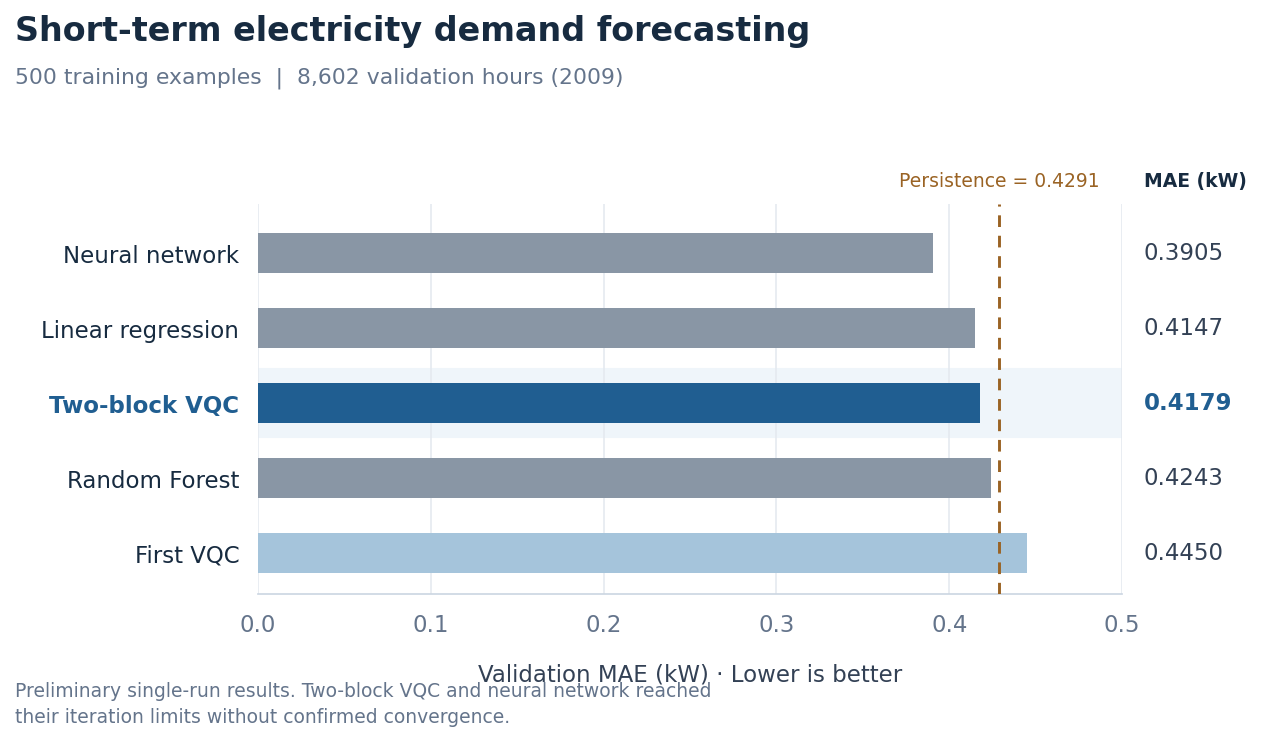

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MultipleLocator, FormatStrFormatter

# Recorded results: same 500 training examples
models = [
    "Neural network",
    "Linear regression",
    "Two-block VQC",
    "Random Forest",
    "First VQC"
]
mae = np.array([0.3905, 0.4147, 0.4179, 0.4243, 0.4450])
persistence_mae = 0.4291

# Muted classical models; blue quantum models
colors = ["#8996A5", "#8996A5", "#205E91", "#8996A5", "#A5C4DB"]

with plt.rc_context({
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "axes.labelcolor": "#334155",
    "text.color": "#172B40",
    "xtick.color": "#64748B",
    "ytick.color": "#172B40",
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
}):
    fig, ax = plt.subplots(figsize=(9, 5.2), dpi=150)
    fig.subplots_adjust(left=0.24, right=0.88, top=0.73, bottom=0.23)

    y = np.arange(len(models))

    # Subtle emphasis on the new circuit
    ax.axhspan(1.55, 2.45, color="#EFF5FA", zorder=0)

    ax.barh(y, mae, height=0.54, color=colors, zorder=3)
    ax.set_yticks(y, labels=models)
    ax.set_ylim(len(models) - 0.45, -0.65)
    ax.set_xlim(0, 0.50)

    # Baseline label above the plot, away from bars and values
    ax.axvline(
        persistence_mae, color="#9A6324",
        linewidth=1.4, linestyle=(0, (4, 3)), zorder=4
    )
    ax.text(
        persistence_mae, 1.035,
        "Persistence = 0.4291",
        transform=ax.get_xaxis_transform(),
        ha="center", va="bottom", fontsize=9, color="#9A6324"
    )

    # Aligned numeric column outside the plotting area
    ax.text(
        1.025, 1.035, "MAE (kW)",
        transform=ax.transAxes,
        fontsize=9, fontweight="bold", va="bottom"
    )
    for i, value in enumerate(mae):
        ax.text(
            1.025, i, f"{value:.4f}",
            transform=ax.get_yaxis_transform(),
            va="center", fontsize=11,
            fontweight="bold" if i == 2 else "normal",
            color="#205E91" if i == 2 else "#334155"
        )

    ax.get_yticklabels()[2].set_fontweight("bold")
    ax.get_yticklabels()[2].set_color("#205E91")

    ax.xaxis.set_major_locator(MultipleLocator(0.1))
    ax.xaxis.set_major_formatter(FormatStrFormatter("%.1f"))
    ax.grid(axis="x", color="#E5EAF0", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="both", length=0, pad=9)

    for side in ["top", "right", "left"]:
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color("#CBD5E1")
    ax.set_xlabel("Validation MAE (kW) · Lower is better", labelpad=13)

    fig.text(
        0.06, 0.94, "Short-term electricity demand forecasting",
        fontsize=16, fontweight="bold", ha="left"
    )
    fig.text(
        0.06, 0.885,
        "500 training examples  |  8,602 validation hours (2009)",
        fontsize=10.5, color="#64748B"
    )
    fig.text(
        0.06, 0.065,
        "Preliminary single-run results. Two-block VQC and neural network reached\n"
        "their iteration limits without confirmed convergence.",
        fontsize=9, color="#64748B", linespacing=1.5
    )

    fig.savefig("forecast_comparison_polished.png",
                dpi=400, bbox_inches="tight", facecolor="white")
    fig.savefig("forecast_comparison_polished.pdf",
                bbox_inches="tight", facecolor="white")
    plt.show()

In [ ]:
from time import perf_counter
from scipy.optimize import minimize

# Continue from the trained parameters; preserve the original result
start_time_extended = perf_counter()

quantum_result_v2_extended = minimize(
    quantum_mse_v2,
    quantum_parameters_v2.copy(),
    args=(X_quantum_train, y_quantum_train),
    method="L-BFGS-B",
    options={"maxiter": 50}
)

extended_seconds = perf_counter() - start_time_extended
quantum_parameters_v2_extended = quantum_result_v2_extended.x.copy()

print(f"Previous training MSE: {quantum_result_v2.fun:.4f} kW²")
print(f"New training MSE: {quantum_result_v2_extended.fun:.4f} kW²")
print(f"Additional iterations: {quantum_result_v2_extended.nit}")
print(f"Additional training time: {extended_seconds:.1f} seconds")
print(f"Optimizer success: {quantum_result_v2_extended.success}")
print(f"Optimizer message: {quantum_result_v2_extended.message}")

Previous training MSE: 0.4215 kW²
New training MSE: 0.4214 kW²
Additional iterations: 50
Additional training time: 476.6 seconds
Optimizer success: False
Optimizer message: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT


In [ ]:
predictions_quantum_v2_extended = predict_quantum_v2(
    X_validation_angles,
    quantum_parameters_v2_extended
)

mae_quantum_v2_extended = np.mean(
    np.abs(
        validation_four["demand_kw"].to_numpy()
        - predictions_quantum_v2_extended
    )
)

print(f"Original validation MAE: {mae_quantum_v2:.4f} kW")
print(f"Extended-training validation MAE: {mae_quantum_v2_extended:.4f} kW")
print(
    f"Total training time: "
    f"{training_seconds_v2 + extended_seconds:.1f} seconds"
)

Original validation MAE: 0.4177 kW
Extended-training validation MAE: 0.4186 kW
Total training time: 941.8 seconds


I restarted L-BFGS-B from the two-block VQC’s learned parameters and allowed 50 additional iterations. Training MSE decreased slightly from 0.4215 to 0.4214 kW², while validation MAE increased from 0.4179 to 0.4182 kW. Total training time reached 636.2 seconds. The optimizer again reached its iteration limit without confirmed convergence. This run showed no validation benefit from additional training, so I retained the original model for subsequent comparisons.

In [ ]:
import numpy as np
from scipy.optimize import minimize
from time import perf_counter

# Same experiment, different starting weights
rng_seed7 = np.random.default_rng(7)
initial_parameters_seed7 = np.concatenate([
    rng_seed7.uniform(-0.5, 0.5, size=8),
    [2.0, 1.0]
])

seed7_progress = {"iteration": 0}

def show_seed7_progress(parameters):
    seed7_progress["iteration"] += 1
    iteration = seed7_progress["iteration"]

    if iteration == 1 or iteration % 5 == 0:
        elapsed = perf_counter() - start_seed7
        print(
            f"Iteration {iteration}/50 | Elapsed: {elapsed:.0f} seconds",
            flush=True
        )

print("Training started. Please let this cell finish.", flush=True)
start_seed7 = perf_counter()

quantum_result_seed7 = minimize(
    quantum_mse_v2,
    initial_parameters_seed7,
    args=(X_quantum_train, y_quantum_train),
    method="L-BFGS-B",
    callback=show_seed7_progress,
    options={"maxiter": 50}
)

training_seconds_seed7 = perf_counter() - start_seed7

print("Training finished. Checking validation predictions...", flush=True)

predictions_seed7 = predict_quantum_v2(
    X_validation_angles,
    quantum_result_seed7.x
)

mae_seed7 = np.mean(
    np.abs(
        validation_four["demand_kw"].to_numpy()
        - predictions_seed7
    )
)

print(f"\nSeed 7 training MSE: {quantum_result_seed7.fun:.4f} kW²")
print(f"Seed 7 validation MAE: {mae_seed7:.4f} kW")
print(f"Seed 42 validation MAE: {mae_quantum_v2:.4f} kW")
print(f"Training time: {training_seconds_seed7:.1f} seconds")
print(f"Iterations: {quantum_result_seed7.nit}")
print(f"Optimizer success: {quantum_result_seed7.success}")
print(f"Optimizer message: {quantum_result_seed7.message}")

Training started. Please let this cell finish.
Iteration 1/50 | Elapsed: 16 seconds
Iteration 5/50 | Elapsed: 47 seconds
Iteration 10/50 | Elapsed: 88 seconds
Iteration 15/50 | Elapsed: 128 seconds
Iteration 20/50 | Elapsed: 177 seconds
Iteration 25/50 | Elapsed: 242 seconds
Iteration 30/50 | Elapsed: 282 seconds
Iteration 35/50 | Elapsed: 346 seconds
Iteration 40/50 | Elapsed: 386 seconds
Iteration 45/50 | Elapsed: 435 seconds
Iteration 50/50 | Elapsed: 483 seconds
Training finished. Checking validation predictions...

Seed 7 training MSE: 0.4230 kW²
Seed 7 validation MAE: 0.4191 kW
Seed 42 validation MAE: 0.4177 kW
Training time: 482.7 seconds
Iterations: 50
Optimizer success: False
Optimizer message: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT


Initialization check: I repeated the two-block VQC experiment with seed 7, keeping the training examples, preprocessing, circuit, and iteration limit unchanged. Validation MAE was 0.4193 kW, compared with 0.4179 kW for seed 42. Training took 330.5 seconds and reached the iteration limit. These two runs produced similar validation errors, providing preliminary evidence of limited sensitivity to initialization under the current settings.

# 8. Corrected limited-data experiment

Scaler fitted on exactly the selected 500 training rows. Five-seed classical results and one corrected VQC run are stored below.


## Forecasting experiment protocol — planned final evaluation

### Objective
Compare classical and variational quantum demand forecasting under
matched data conditions, and assess sensitivity to initialization.

### Data
- Training period: 2007–2008.
- Validation period: 2009.
- Final test period: 2010, kept unused during model development.
- Inputs: previous-hour demand, previous-day demand,
  sine of hour, and cosine of hour.
- Use identical evaluation timestamps for every model.

### Limited-data comparison
- Fix the same 500 training examples for all trained models.
- Fit preprocessing only on these 500 examples.
- Apply the fitted preprocessing to validation and test inputs.

### Models
- Persistence reference.
- Linear regression.
- Random Forest.
- Small neural network.
- One-block and two-block VQC.

### Repeated runs
- Use seeds 42, 7, 21, 123, and 2026 for stochastic models.
- Keep the training sample fixed while varying model randomness.
- Report every run, not only the best.
- These repeats measure model randomness, not training-sample uncertainty.

### Reporting
- Primary forecasting metric: MAE in kW.
- Record training objective, runtime, iterations, and convergence status.
- Summarize repeated runs with mean and sample standard deviation.
- Document training budgets and any changes before running comparisons.
- Use validation for development; reserve test results for final evaluation.

### Status of earlier results
Earlier experiments are exploratory pilot results.
They must remain documented separately from the final comparison.

In [ ]:
from sklearn.preprocessing import StandardScaler
import numpy as np

# Preserve the exact same 500 selected examples
train_500_final = train_four.iloc[quantum_train_indices].copy()

X_train_500_final = train_500_final[features_four].to_numpy()
y_train_500_final = train_500_final["demand_kw"].to_numpy()

X_val_final = validation_four[features_four].to_numpy()
y_val_final = validation_four["demand_kw"].to_numpy()

# Learn preprocessing from these 500 examples only
scaler_500_final = StandardScaler()

X_train_500_scaled_final = scaler_500_final.fit_transform(
    X_train_500_final
)
X_val_scaled_final = scaler_500_final.transform(X_val_final)

# Convert scaled inputs into angles for the quantum circuits
X_train_500_angles_final = np.arctan(X_train_500_scaled_final)
X_val_angles_final = np.arctan(X_val_scaled_final)

# Check that the inputs are usable
assert len(train_500_final) == 500
assert np.isfinite(X_train_500_scaled_final).all()
assert np.isfinite(X_val_scaled_final).all()
assert np.isfinite(y_train_500_final).all()
assert np.isfinite(y_val_final).all()

print("Training examples:", len(train_500_final))
print("Validation examples:", len(validation_four))
print("Examples used to fit scaler:", scaler_500_final.n_samples_seen_)
print("Input features:", features_four)
print("Preprocessing checks passed.")

Training examples: 500
Validation examples: 8602
Examples used to fit scaler: 500
Input features: ['previous_hour_kw', 'previous_day_kw', 'hour_sin', 'hour_cos']
Preprocessing checks passed.


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
import pandas as pd

# Persistence: predict that demand equals the previous hour
pred_persistence_final = validation_four["previous_hour_kw"].to_numpy()

# Linear regression: learn from the same 500 examples
linear_500_final = LinearRegression()
linear_500_final.fit(X_train_500_final, y_train_500_final)

pred_linear_final = linear_500_final.predict(X_val_final)

baseline_results_final = pd.DataFrame({
    "Model": ["Persistence", "Linear regression"],
    "Validation MAE (kW)": [
        mean_absolute_error(y_val_final, pred_persistence_final),
        mean_absolute_error(y_val_final, pred_linear_final)
    ]
})

display(
    baseline_results_final.style.format({
        "Validation MAE (kW)": "{:.4f}"
    })
)

,Model,Validation MAE (kW)
0,Persistence,0.4291
1,Linear regression,0.4147


In [ ]:
import warnings
from time import perf_counter
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

experiment_seeds = [42, 7, 21, 123, 2026]
mlp_models_final = {}
mlp_records_final = []

for seed in experiment_seeds:
    model = MLPRegressor(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        max_iter=500,
        random_state=seed
    )

    start = perf_counter()

    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(X_train_500_scaled_final, y_train_500_final)

    training_seconds = perf_counter() - start

    convergence_warning = any(
        issubclass(w.category, ConvergenceWarning)
        for w in captured
    )

    predictions = model.predict(X_val_scaled_final)
    mae = mean_absolute_error(y_val_final, predictions)

    mlp_models_final[seed] = model
    mlp_records_final.append({
        "Seed": seed,
        "Validation MAE (kW)": mae,
        "Iterations": model.n_iter_,
        "Training seconds": training_seconds,
        "Convergence warning": convergence_warning
    })

    print(f"Seed {seed} complete | Validation MAE: {mae:.4f} kW")

mlp_results_final = pd.DataFrame(mlp_records_final)

display(mlp_results_final.round(4))

print(
    "Mean validation MAE:",
    f"{mlp_results_final['Validation MAE (kW)'].mean():.4f} kW"
)
print(
    "Sample standard deviation:",
    f"{mlp_results_final['Validation MAE (kW)'].std(ddof=1):.4f} kW"
)

Seed 42 complete | Validation MAE: 0.3917 kW
Seed 7 complete | Validation MAE: 0.3938 kW
Seed 21 complete | Validation MAE: 0.3944 kW
Seed 123 complete | Validation MAE: 0.4044 kW
Seed 2026 complete | Validation MAE: 0.3954 kW


,Seed,Validation MAE (kW),Iterations,Training seconds,Convergence warning
0,42,0.3917,500,0.5734,False
1,7,0.3938,500,0.6291,True
2,21,0.3944,500,0.6177,True
3,123,0.4044,240,0.3532,False
4,2026,0.3954,442,0.5559,False


Mean validation MAE: 0.3960 kW
Sample standard deviation: 0.0049 kW


With preprocessing fitted exclusively on the 500 training examples, the neural network achieved a mean validation MAE of 0.3960 kW and sample standard deviation of 0.0049 kW across five predefined seeds. Individual MAEs ranged from 0.3917 to 0.4044 kW. Two runs raised convergence warnings under the fixed 500-iteration budget.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

forest_models_final = {}
forest_records_final = []

for seed in experiment_seeds:
    model = RandomForestRegressor(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=5,
        random_state=seed,
        n_jobs=-1
    )

    start = perf_counter()

    # Trees use the original inputs, without scaling
    model.fit(X_train_500_final, y_train_500_final)

    training_seconds = perf_counter() - start
    predictions = model.predict(X_val_final)
    mae = mean_absolute_error(y_val_final, predictions)

    forest_models_final[seed] = model
    forest_records_final.append({
        "Seed": seed,
        "Validation MAE (kW)": mae,
        "Training seconds": training_seconds
    })

    print(f"Seed {seed} complete | Validation MAE: {mae:.4f} kW")

forest_results_final = pd.DataFrame(forest_records_final)
display(forest_results_final.round(4))

print(
    "Mean validation MAE:",
    f"{forest_results_final['Validation MAE (kW)'].mean():.4f} kW"
)
print(
    "Sample standard deviation:",
    f"{forest_results_final['Validation MAE (kW)'].std(ddof=1):.4f} kW"
)

Seed 42 complete | Validation MAE: 0.4243 kW
Seed 7 complete | Validation MAE: 0.4266 kW
Seed 21 complete | Validation MAE: 0.4234 kW
Seed 123 complete | Validation MAE: 0.4220 kW
Seed 2026 complete | Validation MAE: 0.4208 kW


,Seed,Validation MAE (kW),Training seconds
0,42,0.4243,0.2443
1,7,0.4266,0.2097
2,21,0.4234,0.2158
3,123,0.4220,0.2897
4,2026,0.4208,0.4104


Mean validation MAE: 0.4234 kW
Sample standard deviation: 0.0023 kW


In [ ]:
# Corrected experiment: two-block VQC, seed 42
rng_vqc_final42 = np.random.default_rng(42)

initial_vqc_final42 = np.concatenate([
    rng_vqc_final42.uniform(-0.5, 0.5, size=8),
    [2.0, 1.0]
])

progress_vqc_final42 = {"iteration": 0}

def report_vqc_final42(parameters):
    progress_vqc_final42["iteration"] += 1
    iteration = progress_vqc_final42["iteration"]

    if iteration == 1 or iteration % 10 == 0:
        elapsed = perf_counter() - start_vqc_final42
        print(
            f"Iteration {iteration}/50 | {elapsed:.0f} seconds",
            flush=True
        )

print("Training two-block VQC with corrected inputs...", flush=True)
start_vqc_final42 = perf_counter()

result_vqc_final42 = minimize(
    quantum_mse_v2,
    initial_vqc_final42,
    args=(X_train_500_angles_final, y_train_500_final),
    method="L-BFGS-B",
    callback=report_vqc_final42,
    options={"maxiter": 50}
)

seconds_vqc_final42 = perf_counter() - start_vqc_final42

print("Training finished. Evaluating validation data...", flush=True)

pred_vqc_final42 = predict_quantum_v2(
    X_val_angles_final,
    result_vqc_final42.x
)

mae_vqc_final42 = mean_absolute_error(
    y_val_final, pred_vqc_final42
)

print(f"Training MSE: {result_vqc_final42.fun:.4f} kW²")
print(f"Validation MAE: {mae_vqc_final42:.4f} kW")
print(f"Training time: {seconds_vqc_final42:.1f} seconds")
print(f"Iterations: {result_vqc_final42.nit}")
print(f"Optimizer success: {result_vqc_final42.success}")
print(f"Optimizer message: {result_vqc_final42.message}")

Training two-block VQC with corrected inputs...
Iteration 1/50 | 17 seconds
Iteration 10/50 | 105 seconds
Iteration 20/50 | 202 seconds
Iteration 30/50 | 292 seconds
Iteration 40/50 | 390 seconds
Iteration 50/50 | 478 seconds
Training finished. Evaluating validation data...
Training MSE: 0.4177 kW²
Validation MAE: 0.4149 kW
Training time: 478.4 seconds
Iterations: 50
Optimizer success: False
Optimizer message: STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT


# 9. Next milestone — battery scheduling

Not implemented yet. Follow `docs/ROADMAP.md`: define a four-hour scenario, implement energy balance and battery constraints, verify exact enumeration, then formulate QAOA on the identical discrete problem. Do not interpret the forecasting results as operational savings.
